# 7. Compare the models

**Rule:** we choose the best model using **validation AUC**, and then report its test result. Choosing by test score would make that score look better than it really is.

Sensitivity is fixed at about 90% on validation data, so specificity shows how many false alarms each model raises at that level.

Run this after notebooks 3 to 6. It compares whichever results it finds.

In [11]:
%pip install -q numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "DeepDRiD" / "regular_fundus_images"
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
for folder in (PROCESSED, RESULTS, MODELS):
    folder.mkdir(parents=True, exist_ok=True)
print("Project folder:", ROOT)

Project folder: c:\Users\Administrator\Desktop\AfriEyeSamsung


In [13]:
import json

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

In [14]:
import matplotlib.pyplot as plt

BLUE, TEAL, ORANGE, PURPLE = "#1F4E9E", "#00948F", "#C4581F", "#7A3E9D"
INK, MUTED, GRID = "#1B2433", "#566173", "#E3E7F0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.edgecolor": "#AEB6C5", "axes.labelcolor": MUTED, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "legend.frameon": False,
})

In [15]:
ORDER = [("linear_regression", BLUE), ("logistic_regression", TEAL), ("random_forest", ORANGE), ("xgboost", PURPLE)]
found = [(slug, color) for slug, color in ORDER if (RESULTS / f"{slug}_metrics.json").exists()]
metrics = {slug: json.loads((RESULTS / f"{slug}_metrics.json").read_text()) for slug, _ in found}
COLORS = {metrics[slug]["model"]: color for slug, color in found}
print("Models found:", [metrics[s]["model"] for s, _ in found])
missing = [slug for slug, _ in ORDER if slug not in metrics]
if missing:
    print("Not run yet:", missing)

table = pd.DataFrame([{
    "Model": m["model"], "Val AUC": m["val_auc"], "Test AUC": m["test_auc"],
    "Test AUC 95% CI": f"{m['test_auc_ci'][0]:.2f} to {m['test_auc_ci'][1]:.2f}",
    "Test sensitivity": m["test_sensitivity"], "Test specificity": m["test_specificity"],
    "Severe missed": f"{m['missed_severe_or_worse']} of {m['severe_or_worse']}", "Train seconds": m["seconds_to_train"],
} for m in metrics.values()]).sort_values("Val AUC", ascending=False)
table.to_csv(RESULTS / "model_comparison.csv", index=False)
show = table.copy()
for c in ("Val AUC", "Test AUC"): show[c] = show[c].map("{:.3f}".format)
for c in ("Test sensitivity", "Test specificity"): show[c] = show[c].map("{:.1%}".format)
show["Train seconds"] = show["Train seconds"].map("{:.1f}".format)
print(show.to_string(index=False))

Models found: ['Linear regression', 'Logistic regression', 'Random forest', 'XGBoost']
              Model Val AUC Test AUC Test AUC 95% CI Test sensitivity Test specificity Severe missed Train seconds
  Linear regression   0.868    0.901    0.85 to 0.94            93.9%            69.1%       6 of 92           0.1
Logistic regression   0.868    0.899    0.85 to 0.94            94.5%            68.6%       7 of 92           7.6
            XGBoost   0.856    0.889    0.84 to 0.93            94.5%            67.4%       7 of 92          64.4
      Random forest   0.835    0.877    0.82 to 0.93            91.5%            69.1%      10 of 92         121.3


## Test AUC with 95% confidence intervals

If the intervals overlap heavily, this test set can't clearly separate those models.

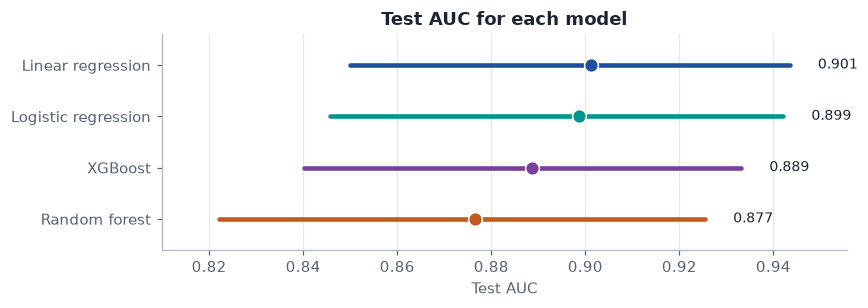

In [16]:
ordered = sorted(metrics.values(), key=lambda m: m["test_auc"])
fig, ax = plt.subplots(figsize=(8, 2.9))
for i, m in enumerate(ordered):
    low, high = m["test_auc_ci"]
    ax.plot([low, high], [i, i], color=COLORS[m["model"]], linewidth=3, solid_capstyle="round")
    ax.plot(m["test_auc"], i, "o", color=COLORS[m["model"]], markersize=9, markeredgecolor="white")
    ax.text(high + .006, i, f"{m['test_auc']:.3f}", va="center", color=INK, fontsize=9)
ax.set_yticks(range(len(ordered)), [m["model"] for m in ordered]); ax.set_xlabel("Test AUC"); ax.set_title("Test AUC for each model"); ax.grid(axis="y", visible=False); ax.margins(y=.2, x=.1)
fig.tight_layout(); plt.show()

## ROC curves on the test photos

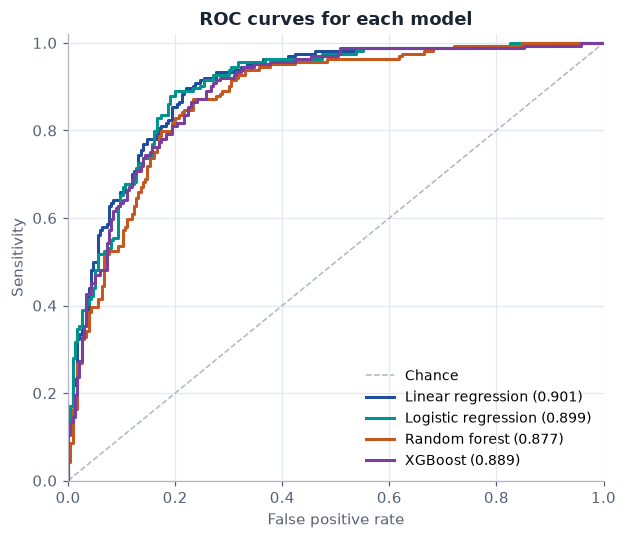

In [17]:
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.plot([0, 1], [0, 1], color="#AEB6C5", linestyle="--", linewidth=1, label="Chance")
for slug, color in found:
    p = pd.read_csv(RESULTS / f"{slug}_predictions.csv"); p = p[p.split == "test"]
    fpr, tpr, _ = roc_curve(p.referable, p.score)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{metrics[slug]['model']} ({metrics[slug]['test_auc']:.3f})")
ax.set(xlabel="False positive rate", ylabel="Sensitivity", xlim=(0, 1), ylim=(0, 1.02), title="ROC curves for each model"); ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); plt.show()

## Sensitivity and specificity

These use each model's own validation threshold.

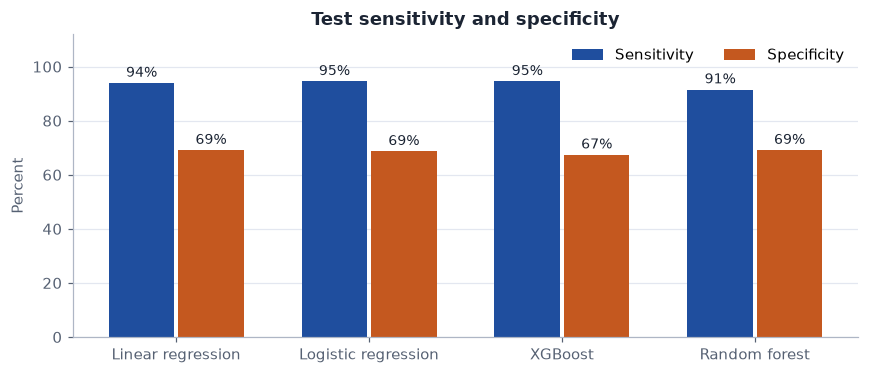

In [18]:
names = list(table.Model); x = np.arange(len(names)); width = .36
fig, ax = plt.subplots(figsize=(8, 3.5))
a = ax.bar(x - width / 2, table["Test sensitivity"] * 100, width - .02, color=BLUE, label="Sensitivity")
b = ax.bar(x + width / 2, table["Test specificity"] * 100, width - .02, color=ORANGE, label="Specificity")
ax.bar_label(a, fmt="%.0f%%", padding=2, fontsize=9, color=INK); ax.bar_label(b, fmt="%.0f%%", padding=2, fontsize=9, color=INK)
ax.set_xticks(x, names); ax.set_ylim(0, 112); ax.set_ylabel("Percent"); ax.set_title("Test sensitivity and specificity"); ax.grid(axis="x", visible=False); ax.legend(ncols=2, loc="upper right")
fig.tight_layout(); plt.show()

## Do the models still work within each image size?

Image size may point to the camera or clinic. If AUC falls sharply within one size group, the overall score is partly coming from differences between groups, not only from signs of disease.

              Model  Image size  Photos % referable   AUC
  Linear regression 1736 x 1824     262          25 0.917
  Linear regression 1976 x 1984     132          73 0.679
Logistic regression 1736 x 1824     262          25 0.915
Logistic regression 1976 x 1984     132          73 0.677
      Random forest 1736 x 1824     262          25 0.864
      Random forest 1976 x 1984     132          73 0.716
            XGBoost 1736 x 1824     262          25 0.877
            XGBoost 1976 x 1984     132          73 0.756


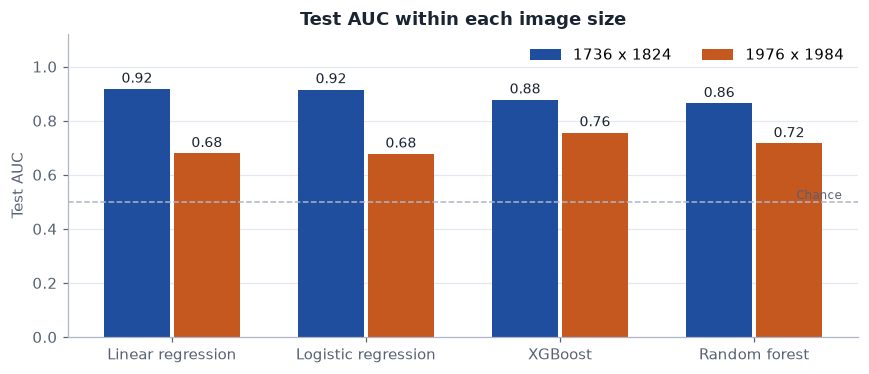

In [19]:
labels = pd.read_csv(PROCESSED / "clean_labels.csv")
labels["image_size"] = labels.width.astype(int).astype(str) + " x " + labels.height.astype(int).astype(str)
rows = []
for slug, _ in found:
    p = pd.read_csv(RESULTS / f"{slug}_predictions.csv").merge(labels[["image_id", "image_size"]], on="image_id")
    for size, g in p[p.split == "test"].groupby("image_size"):
        if len(g) >= 30 and 0 < g.referable.sum() < len(g):
            rows.append({"Model": metrics[slug]["model"], "Image size": size, "Photos": len(g), "% referable": g.referable.mean() * 100, "AUC": roc_auc_score(g.referable, g.score)})
within = pd.DataFrame(rows)
print(within.to_string(index=False, formatters={"% referable": "{:.0f}".format, "AUC": "{:.3f}".format}))

sizes = sorted(within["Image size"].unique()); names = list(table.Model); x = np.arange(len(names)); width = .36
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, (size, color) in enumerate(zip(sizes, [BLUE, ORANGE])):
    values = [within[(within.Model == n) & (within["Image size"] == size)].AUC.iloc[0] for n in names]
    bars = ax.bar(x + (i - .5) * width, values, width - .02, color=color, label=size)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9, color=INK)
ax.axhline(.5, color="#AEB6C5", linestyle="--", linewidth=1); ax.text(len(names) - .55, .51, "Chance", fontsize=8, color=MUTED, ha="right")
ax.set_xticks(x, names); ax.set_ylim(0, 1.12); ax.set_ylabel("Test AUC"); ax.set_title("Test AUC within each image size"); ax.grid(axis="x", visible=False); ax.legend(ncols=2, loc="upper right")
fig.tight_layout(); plt.show()

## The result

In [20]:
best = table.iloc[0]
tied = table[table["Val AUC"] >= best["Val AUC"] - 0.005].Model.tolist()
if len(tied) > 1:
    print("These models are effectively tied on validation AUC:", ", ".join(tied))
print(f"Best by validation AUC: {best.Model}")
print(f"Validation AUC {best['Val AUC']:.3f} | Test AUC {best['Test AUC']:.3f} ({best['Test AUC 95% CI']})")
print(f"Test sensitivity {best['Test sensitivity']:.1%} | Test specificity {best['Test specificity']:.1%} | Severe missed {best['Severe missed']}")

These models are effectively tied on validation AUC: Linear regression, Logistic regression
Best by validation AUC: Linear regression
Validation AUC 0.868 | Test AUC 0.901 (0.85 to 0.94)
Test sensitivity 93.9% | Test specificity 69.1% | Severe missed 6 of 92


## How to read this honestly

- **Same data:** all test photos come from DeepDRiD. These scores may fall on adapter photos and Kenyan patients.
- **Not the final choice yet:** AUC is only part of the decision. Missed severe cases, false alarms, and model size and speed on a phone also matter.
- **Compare with care:** our earlier small neural network reached a test AUC of 0.943 on these same splits, but it isn't part of this notebook set. These four models only see hand-made features.
- **Same warning for the neural network:** its test AUC was 0.95 on 1736 x 1824 photos and 0.81 on 1976 x 1984 photos, so its overall 0.943 needs the same caution.
- **Next experiment:** add neural networks that learn directly from the photos, then compare them all the same way.